# Taller | Clasificación de movimientos manuales con aprendizaje profundo

**Objetivo:** clasificar seis movimientos de la mano a partir de ventanas de señales sEMG de **12 canales × 300 muestras** utilizando una CNN.

**Ruta:** datos → señales → ventanas → normalización → CNN → entrenamiento → evaluación.

Trabajaremos con datos temporales de **NinaPro DB2** y separaremos entrenamiento, validación y prueba **por repeticiones** para evitar que las ventanas de una misma repetición aparezcan en conjuntos distintos. La exactitud que obtengamos será **intra-sujeto** (repeticiones no vistas del mismo sujeto).

> Antes de ejecutar: coloca el archivo `.mat` en la ruta configurada en la primera celda; en Google Colab habrá que cargar el archivo o montarlo desde Drive.

## 1. Bibliotecas y configuración

Aquí seleccionamos el archivo, las clases y los parámetros del experimento. Más adelante podrán experimentar cambiando **épocas máximas** o **tasa de aprendizaje**.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, recall_score
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Conv2D, AveragePooling2D, Dense, Flatten, ReLU
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

SEMILLA = 42
np.random.seed(SEMILLA)
tf.random.set_seed(SEMILLA)

# Ajustar esta ruta (archivo subido o almacenado en drive)
RUTA_MAT = Path('Datos_originales/S1_E1_A1_DB2.mat')

# Clases seleccionadas en este archivo .mat
MOVIMIENTOS = [1, 2, 3, 4, 5, 6]

TAM_VENTANA = 300
PASO = 60  # 80 % de solapamiento: (300-60)/300 = 0.80
REPS_ENTRENAMIENTO = (1, 3, 6)
REPS_VALIDACION = (4,)
REPS_PRUEBA = (2, 5)

EPOCAS = 35
BATCH_SIZE = 32
TASA_APRENDIZAJE = 0.001

print('TensorFlow:', tf.__version__)
print('Ventana:', TAM_VENTANA, 'muestras; paso:', PASO, 'muestras')

TensorFlow: 2.21.0
Ventana: 300 muestras; paso: 60 muestras


In [4]:
from scipy.io import loadmat

mat = loadmat(
    RUTA_MAT,
    variable_names=['emg', 'restimulus', 'rerepetition']
)

for nombre in ['emg', 'restimulus', 'rerepetition']:
    print(nombre, mat[nombre].shape)

emg (1808331, 12)
restimulus (1808331, 1)
rerepetition (1808331, 1)


## 2. Carga y verificación de datos

El archivo de NinaPro contiene las señales en orden de adquisición (`emg`) y las etiquetas de movimiento y repetición (`restimulus` y `rerepetition`, cuando están disponibles). Comprobamos que existan **12 canales** y las seis clases seleccionadas.

In [5]:
if not RUTA_MAT.is_file():
    raise FileNotFoundError(
        f'Falta {RUTA_MAT}. Descarga/descomprime el archivo original de NinaPro y cambia RUTA_MAT. '
        'El CSV mezclado no es una alternativa válida para ventanas temporales.'
    )

mat = loadmat(
    RUTA_MAT,
    variable_names=['emg', 'restimulus', 'rerepetition']
)

print("Variables cargadas:", list(mat.keys()))

CLAVE_CLASE = 'restimulus' if 'restimulus' in mat else 'stimulus'
CLAVE_REP = 'rerepetition' if 'rerepetition' in mat else 'repetition'

for clave in ('emg', CLAVE_CLASE, CLAVE_REP):
    if clave not in mat:
        raise KeyError(f'Falta la variable {clave}. Revisa qué contiene el .mat.')

emg = np.asarray(mat['emg'], dtype=np.float32)
clases = np.asarray(mat[CLAVE_CLASE]).reshape(-1).astype(int)
repeticiones = np.asarray(mat[CLAVE_REP]).reshape(-1).astype(int)

if emg.ndim != 2 or emg.shape[1] != 12:
    raise ValueError(f'Se esperaban 12 canales; se encontró {emg.shape}.')
if not (len(emg) == len(clases) == len(repeticiones)):
    raise ValueError('Las señales, clases y repeticiones no están alineadas.')
if len(set(MOVIMIENTOS)) != 6:
    raise ValueError('Selecciona seis etiquetas de movimiento distintas.')
if not np.isfinite(emg).all():
    raise ValueError('Los datos contienen NaN o infinitos. Revisa el archivo.')

print('Señales:', emg.shape)
print('Clases disponibles:', np.unique(clases))
print('Repeticiones disponibles:', np.unique(repeticiones))
print('Clases elegidas:', MOVIMIENTOS)

resumen = pd.crosstab(clases, repeticiones)
display(resumen.loc[resumen.index.intersection(MOVIMIENTOS)])

for clase in MOVIMIENTOS:
    for rep in (*REPS_ENTRENAMIENTO, *REPS_VALIDACION, *REPS_PRUEBA):
        if not np.any((clases == clase) & (repeticiones == rep)):
            raise ValueError(f'No hay muestras para movimiento {clase}, repetición {rep}. '
                             'Cambia MOVIMIENTOS o comprueba la disponibilidad de ese gesto.')

Variables cargadas: ['__header__', '__version__', '__globals__', 'emg', 'restimulus', 'rerepetition']
Señales: (1808331, 12)
Clases disponibles: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17]
Repeticiones disponibles: [0 1 2 3 4 5 6]
Clases elegidas: [1, 2, 3, 4, 5, 6]


col_0,0,1,2,3,4,5,6
row_0,,,,,,,
1,0,14221,12924,12852,12965,12910,12829
2,0,13003,11905,7089,10912,8245,7825
3,0,9205,8069,7884,8046,8910,8871
4,0,6671,5924,8587,8062,8249,7572
5,0,7026,7029,7405,6727,6351,5587
6,0,4485,4506,4345,4346,3929,3946


## 3. Visualización de las 12 señales sEMG

Cada curva corresponde a un electrodo. Se muestra hasta un segundo **consecutivo** de una sola ejecución. El escalado por canal se usa **únicamente para visualizar**; no se emplea para entrenar.

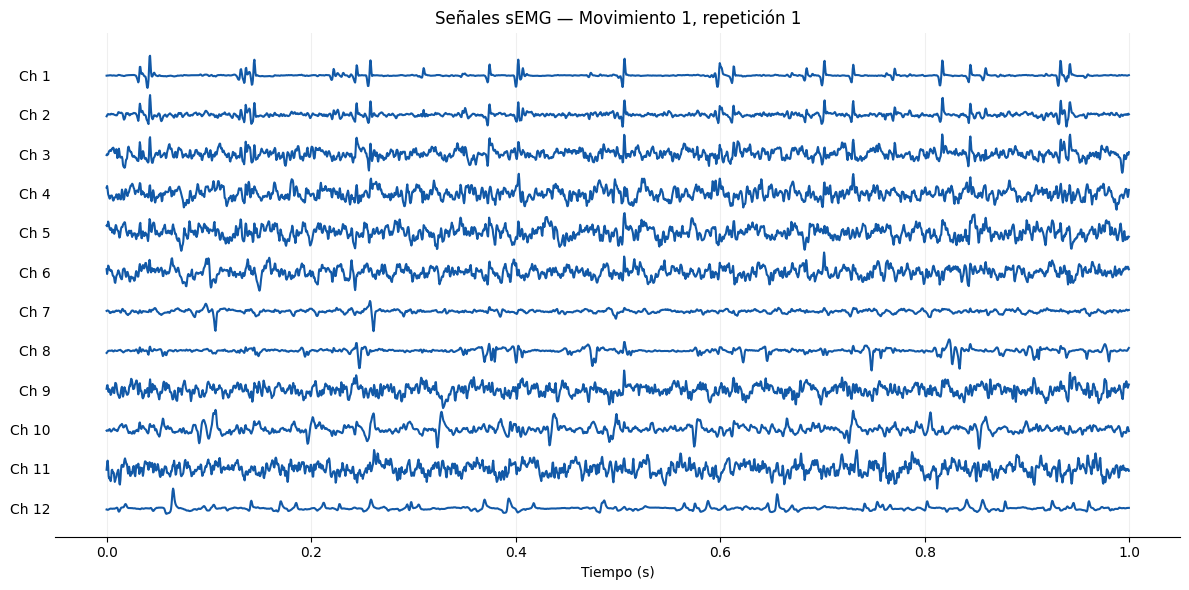

In [6]:
# Elegir una ejecución concreta y encontrar su primer tramo continuo.
movimiento_ejemplo = MOVIMIENTOS[0]
rep_ejemplo = REPS_ENTRENAMIENTO[0]
indices = np.flatnonzero((clases == movimiento_ejemplo) & (repeticiones == rep_ejemplo))
primer_corte = np.flatnonzero(np.diff(indices) != 1)
fin_primero = primer_corte[0] + 1 if len(primer_corte) else len(indices)
tramo_indices = indices[:fin_primero]

if len(tramo_indices) < TAM_VENTANA:
    raise ValueError('El tramo elegido tiene menos de 300 muestras.')

fs = 2000  # Hz: NinaPro DB2
senal = emg[tramo_indices[:2000], :]
tiempo = np.arange(len(senal)) / fs
amplitud = np.maximum(np.max(np.abs(senal), axis=0), 1e-12)
senal_vis = senal / amplitud  # Solo para la gráfica

fig, ax = plt.subplots(figsize=(12, 6))
for i in range(12):
    nivel = (11 - i) * 2
    ax.plot(tiempo, senal_vis[:, i] + nivel, color='#1259A7', linewidth=1.5)

ax.set_yticks(np.arange(11, -1, -1) * 2)
ax.set_yticklabels([f'Ch {i+1}' for i in range(12)])
ax.set_xlabel('Tiempo (s)')
ax.set_title(f'Señales sEMG — Movimiento {movimiento_ejemplo}, repetición {rep_ejemplo}')
ax.grid(axis='x', alpha=0.2)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.tick_params(axis='y', length=0)
plt.tight_layout()
plt.savefig('sEMG_12_canales.png', dpi=300, bbox_inches='tight')
plt.show()

## 4. Segmentación y separación por repeticiones

Separamos **antes** de formar las ventanas: entrenamiento = repeticiones 1, 3 y 6; validación = 4; prueba = 2 y 5.

Cada ventana contiene **300 muestras (150 ms a 2 kHz)** de **12 canales**. El desplazamiento de **60 muestras** produce **80 % de solapamiento**. Las ventanas no cruzan cambios de movimiento ni de repetición.

In [7]:
id_clase = {clase: i for i, clase in enumerate(MOVIMIENTOS)}

ventanas = {'train': [], 'val': [], 'test': []}
etiquetas = {'train': [], 'val': [], 'test': []}

cortes = np.where((clases[1:] != clases[:-1]) | (repeticiones[1:] != repeticiones[:-1]))[0] + 1
limites = np.r_[0, cortes, len(clases)]

for inicio, fin in zip(limites[:-1], limites[1:]):
    clase = int(clases[inicio])
    rep = int(repeticiones[inicio])

    if clase not in id_clase:
        continue
    if rep in REPS_ENTRENAMIENTO:
        conjunto = 'train'
    elif rep in REPS_VALIDACION:
        conjunto = 'val'
    elif rep in REPS_PRUEBA:
        conjunto = 'test'
    else:
        continue

    # No cruzar cambios de clase/repetición: las muestras aquí son consecutivas.
    for posicion in range(inicio, fin - TAM_VENTANA + 1, PASO):
        ventanas[conjunto].append(emg[posicion:posicion+TAM_VENTANA, :])
        etiquetas[conjunto].append(id_clase[clase])

X_train = np.asarray(ventanas['train'], dtype=np.float32)
X_val   = np.asarray(ventanas['val'], dtype=np.float32)
X_test  = np.asarray(ventanas['test'], dtype=np.float32)
y_train = np.asarray(etiquetas['train'], dtype=np.int32)
y_val   = np.asarray(etiquetas['val'], dtype=np.int32)
y_test  = np.asarray(etiquetas['test'], dtype=np.int32)

for nombre, x in [('train', X_train), ('val', X_val), ('test', X_test)]:
    if x.ndim != 3 or x.shape[1:] != (300, 12):
        raise ValueError(f'No se obtuvieron suficientes ventanas válidas para {nombre}: {x.shape}')
    print(f'{nombre}: {x.shape}')

print('Clases codificadas:', id_clase)
print('Ventanas por clase y conjunto:')
print(pd.DataFrame({'train': np.bincount(y_train, minlength=6),
                    'val': np.bincount(y_val, minlength=6),
                    'test': np.bincount(y_test, minlength=6)},
                   index=[f'Mov {m}' for m in MOVIMIENTOS]))

train: (2411, 300, 12)
val: (825, 300, 12)
test: (1596, 300, 12)
Clases codificadas: {1: 0, 2: 1, 3: 2, 4: 3, 5: 4, 6: 5}
Ventanas por clase y conjunto:
       train  val  test
Mov 1    652  212   422
Mov 2    452  177   327
Mov 3    419  130   274
Mov 4    368  130   227
Mov 5    321  108   214
Mov 6    199   68   132


## 5. Normalización y forma de entrada

Calculamos la media y desviación estándar de cada canal **solo con datos de entrenamiento**. Después aplicamos esa transformación a los tres conjuntos. La CNN recibe tensores de forma `(N, 12, 300, 1)`.

In [8]:
mascara_train = np.isin(clases, MOVIMIENTOS) & np.isin(repeticiones, REPS_ENTRENAMIENTO)
escalador = StandardScaler()
escalador.fit(emg[mascara_train])

# StandardScaler trabaja con (filas, 12). Después recuperamos (N, 300, 12).
X_train = escalador.transform(X_train.reshape(-1, 12)).reshape(X_train.shape).astype(np.float32)
X_val   = escalador.transform(X_val.reshape(-1, 12)).reshape(X_val.shape).astype(np.float32)
X_test  = escalador.transform(X_test.reshape(-1, 12)).reshape(X_test.shape).astype(np.float32)

# Transponer SÍ intercambia ejes; reshape a secas NO lo hace.
X_train = X_train.transpose(0, 2, 1)[..., np.newaxis]
X_val   = X_val.transpose(0, 2, 1)[..., np.newaxis]
X_test  = X_test.transpose(0, 2, 1)[..., np.newaxis]

print('Entrenamiento:', X_train.shape)
print('Validación:', X_val.shape)
print('Prueba:', X_test.shape)
assert X_train.shape[1:] == X_val.shape[1:] == X_test.shape[1:] == (12, 300, 1)

Entrenamiento: (2411, 12, 300, 1)
Validación: (825, 12, 300, 1)
Prueba: (1596, 12, 300, 1)


## 6. Arquitectura CNN

Cuatro convoluciones extraen patrones de las señales; dos capas de *average pooling* reducen las dimensiones; `Flatten` convierte los mapas de características en un vector, `Dropout` regulariza y `Softmax` entrega seis probabilidades.

**Nota:** esta versión incorpora `Dropout(0.5)` y corresponde a la variante regularizada usada en el taller.

In [9]:
tf.keras.backend.clear_session()
# Para comparar de forma reproducible esta variante:
tf.random.set_seed(SEMILLA)
modelo = Sequential([
    Input(shape=(12, 300, 1)),
    Conv2D(32, (1, 12), padding='valid'),
    ReLU(),
    Conv2D(32, (3, 3), padding='valid'),
    ReLU(),
    AveragePooling2D(pool_size=(3, 3)),
    Conv2D(64, (5, 5), padding='same'),
    ReLU(),
    AveragePooling2D(pool_size=(3, 3)),
    Conv2D(64, (9, 1), padding='same'),
    ReLU(),
    Flatten(),
    tf.keras.layers.Dropout(0.5),  # Única capa adicional
    Dense(6, activation='softmax')
])

modelo.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=TASA_APRENDIZAJE),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
modelo.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 12, 289, 32)    │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 12, 289, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 10, 287, 32)    │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 10, 287, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 3, 95, 32)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 95, 64)      │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 3, 95, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 1, 31, 64)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 1, 31, 64)      │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 1, 31, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1984)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1984)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │        11,910 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,766 (428.77 KB)

 Trainable params: 109,766 (428.77 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Entrenamiento

La red ajusta sus pesos con el conjunto de entrenamiento. La validación permite observar si mejora con datos de otra repetición. `ReduceLROnPlateau` reduce la tasa de aprendizaje si la pérdida de validación se estanca, y `EarlyStopping` detiene el proceso y recupera los mejores pesos cuando se activa.

**Para repetir desde cero**, vuelve a ejecutar primero la celda que crea y compila la CNN.

In [10]:
callbacks = [
    EarlyStopping(monitor='val_loss', patience=30, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5, verbose=1)
]

historial = modelo.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCAS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/35
76/76 ━━━━━━━━━━━━━━━━━━━━ 28s 348ms/step - accuracy: 0.3965 - loss: 1.4434 - val_accuracy: 0.5879 - val_loss: 1.0852 - learning_rate: 0.0010
Epoch 2/35
76/76 ━━━━━━━━━━━━━━━━━━━━ 24s 323ms/step - accuracy: 0.6242 - loss: 0.9389 - val_accuracy: 0.6994 - val_loss: 0.8488 - learning_rate: 0.0010
Epoch 3/35
76/76 ━━━━━━━━━━━━━━━━━━━━ 41s 317ms/step - accuracy: 0.7101 - loss: 0.7189 - val_accuracy: 0.7552 - val_loss: 0.7772 - learning_rate: 0.0010
Epoch 4/35
76/76 ━━━━━━━━━━━━━━━━━━━━ 42s 330ms/step - accuracy: 0.7785 - loss: 0.5923 - val_accuracy: 0.7794 - val_loss: 0.6984 - learning_rate: 0.0010
Epoch 5/35
76/76 ━━━━━━━━━━━━━━━━━━━━ 40s 323ms/step - accuracy: 0.8084 - loss: 0.5130 - val_accuracy: 0.7842 - val_loss: 0.7212 - learning_rate: 0.0010
Epoch 6/35
76/76 ━━━━━━━━━━━━━━━━━━━━ 23s 301ms/step - accuracy: 0.8158 - loss: 0.4857 - val_accuracy: 0.7952 - val_loss: 0.7240 - learning_rate: 0.0010
Epoch 7/35
76/76 ━━━━━━━━━━━━━━━━━━━━ 42s 320ms/step - accuracy: 0.8391 - loss: 0.

## 8. Curvas de aprendizaje

Compara la exactitud y pérdida de entrenamiento con las de validación. Una separación creciente entre ambas puede indicar **sobreajuste**. El mejor modelo se selecciona según **`val_loss`**.

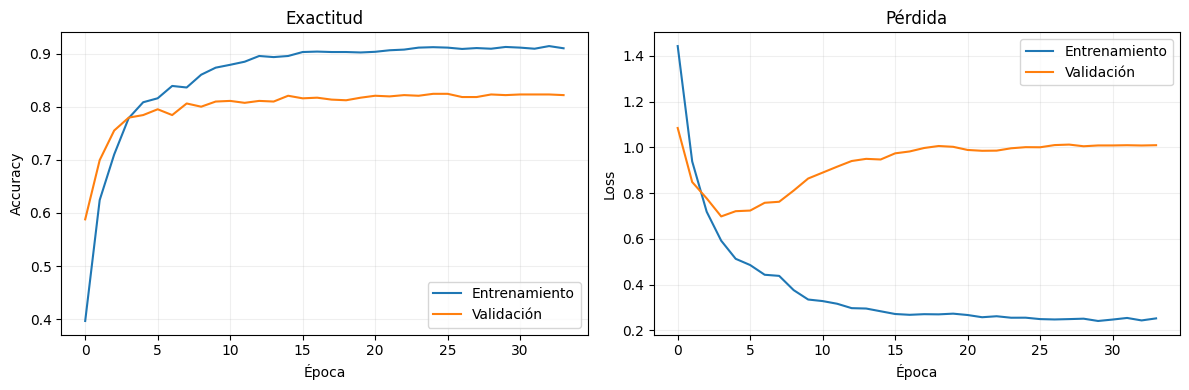

Mejor época según val_loss: 4
Mejor val_loss: 0.6984
Mayor val_accuracy observada: 82.42%
Pesos actuales: train=82.414%, val=77.939%
Diferencia: 4.47 puntos porcentuales


In [11]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(historial.history['accuracy'], label='Entrenamiento')
axs[0].plot(historial.history['val_accuracy'], label='Validación')
axs[0].set(title='Exactitud', xlabel='Época', ylabel='Accuracy')
axs[1].plot(historial.history['loss'], label='Entrenamiento')
axs[1].plot(historial.history['val_loss'], label='Validación')
axs[1].set(title='Pérdida', xlabel='Época', ylabel='Loss')
for ax in axs:
    ax.legend()
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig('acc.png', dpi=300, bbox_inches='tight')
plt.show()

mejor_epoca = np.argmin(historial.history['val_loss']) + 1
print('Mejor época según val_loss:', mejor_epoca)
print('Mejor val_loss:', round(float(min(historial.history['val_loss'])), 4))
print('Mayor val_accuracy observada:', f"{max(historial.history['val_accuracy']):.2%}")

# Si detuviste manualmente el entrenamiento, no se garantiza la restauración de pesos.
_, acc_train = modelo.evaluate(X_train, y_train, verbose=0)
_, acc_val = modelo.evaluate(X_val, y_val, verbose=0)
print(f'Pesos actuales: train={acc_train:.3%}, val={acc_val:.3%}')
print(f'Diferencia: {(acc_train-acc_val)*100:.2f} puntos porcentuales')

## 9. Evaluación en prueba

Una vez elegida la configuración mediante validación, evaluamos el modelo **una sola vez** sobre repeticiones reservadas para prueba. Examinamos accuracy, precisión, recall, F1 y la matriz de confusión normalizada.

> **Importante:** estas métricas se calculan de nuevo en cada ejecución. No necesariamente coincidirán con las cifras de una prueba anterior o con las diapositivas.

Test loss: 0.5327
Test accuracy: 79.5113%
              precision    recall  f1-score   support

Movimiento 1       0.75      1.00      0.86       422
Movimiento 2       0.72      0.45      0.55       327
Movimiento 3       0.71      0.74      0.73       274
Movimiento 4       0.85      0.86      0.86       227
Movimiento 5       0.93      0.87      0.90       214
Movimiento 6       1.00      0.89      0.94       132

    accuracy                           0.80      1596
   macro avg       0.83      0.80      0.80      1596
weighted avg       0.80      0.80      0.78      1596



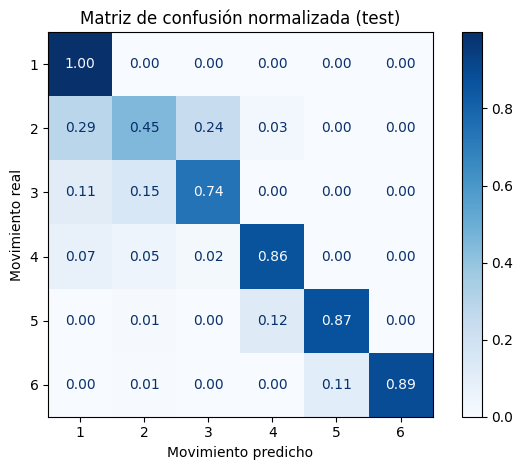

In [12]:
loss_test, acc_test = modelo.evaluate(X_test, y_test, verbose=0)
pred_test = np.argmax(modelo.predict(X_test, verbose=0), axis=1)

print(f'Test loss: {loss_test:.4f}')
print(f'Test accuracy: {acc_test:.4%}')
print(classification_report(y_test, pred_test,
                            labels=np.arange(6),
                            target_names=[f'Movimiento {m}' for m in MOVIMIENTOS],
                            zero_division=0))

cm = confusion_matrix(y_test, pred_test, labels=np.arange(6), normalize='true')
disp = ConfusionMatrixDisplay(cm, display_labels=[str(m) for m in MOVIMIENTOS])
disp.plot(cmap='Blues', values_format='.2f')
plt.title('Matriz de confusión normalizada (test)')
plt.xlabel('Movimiento predicho')
plt.ylabel('Movimiento real')
plt.tight_layout()
plt.show()

### Recall por movimiento

El **recall** muestra qué proporción de las ventanas de cada movimiento se reconoce correctamente. Esta gráfica se calcula **automáticamente a partir de las predicciones actuales**, sin porcentajes escritos a mano.

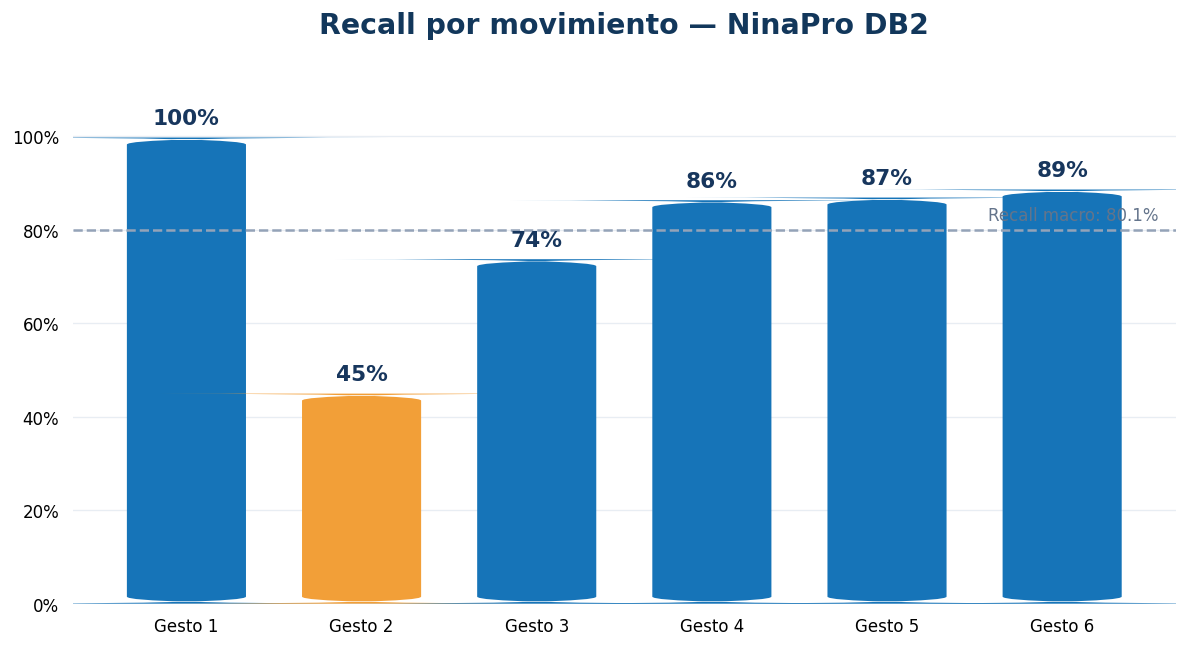

In [13]:
from matplotlib.patches import FancyBboxPatch

recall = recall_score(y_test, pred_test, labels=np.arange(6), average=None,
                      zero_division=0) * 100
x = np.arange(len(MOVIMIENTOS))
promedio = recall.mean()  # Recall macro
peor = int(np.argmin(recall))

fig, ax = plt.subplots(figsize=(10, 5.5), dpi=120)
fig.patch.set_facecolor('white')

for i, valor in enumerate(recall):
    color = '#F29F38' if i == peor else '#1674B8'
    ax.add_patch(FancyBboxPatch((i - 0.34, 0), 0.68, valor,
                                boxstyle='round,pad=0,rounding_size=1.5',
                                linewidth=0, facecolor=color))
    ax.text(i, valor + 2, f'{valor:.0f}%', ha='center', va='bottom',
            fontsize=13, fontweight='bold', color='#17365D')

ax.axhline(promedio, color='#94A3B8', linestyle='--', linewidth=1.5)
ax.text(5.55, promedio + 2, f'Recall macro: {promedio:.1f}%',
        ha='right', fontsize=10, color='#64748B')
ax.set_xlim(-0.65, 5.65)
ax.set_ylim(0, 115)
ax.set_xticks(x)
ax.set_xticklabels([f'Gesto {i+1}' for i in range(6)])
ax.set_yticks(np.arange(0, 101, 20))
ax.set_yticklabels([f'{v}%' for v in range(0, 101, 20)])
ax.set_title('Recall por movimiento — NinaPro DB2', fontsize=17,
             fontweight='bold', color='#12375B', pad=20)
ax.grid(axis='y', color='#E8EDF3')
ax.set_axisbelow(True)
ax.tick_params(axis='both', length=0, pad=8)
for spine in ax.spines.values():
    spine.set_visible(False)
plt.tight_layout()
plt.savefig('recall_DB2.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

## 10. Guardar el modelo y los resultados (opcional)

Este paso es útil para el docente: conserva el modelo entrenado, las curvas y la matriz de confusión. En Colab, los archivos de la sesión son temporales hasta que se descargan o copian a Drive.

In [ ]:
salida = Path('resultados_taller')
salida.mkdir(exist_ok=True)
modelo.save(salida / 'cnn_atzori_12x300.keras')
pd.DataFrame(historial.history).to_csv(salida / 'curvas_entrenamiento.csv', index=False)
pd.DataFrame(cm, index=MOVIMIENTOS, columns=MOVIMIENTOS).to_csv(salida / 'matriz_confusion_test_normalizada.csv')
print('Archivos guardados en:', salida.resolve())

## Para discutir al terminar

1. ¿Por qué utilizamos ventanas de 12 × 300 en lugar de una sola medición por canal?
2. ¿Por qué las repeticiones de prueba no deben estar presentes en entrenamiento?
3. ¿Qué ocurre cuando la exactitud de entrenamiento aumenta, pero la pérdida de validación empeora?
4. ¿Qué movimientos se confunden más? ¿Por qué el accuracy global no cuenta toda la historia?
5. ¿Qué nos faltaría para controlar una prótesis real en tiempo real?

**Experimento opcional:** cambiar `EPOCAS` o `TASA_APRENDIZAJE`, construir de nuevo la red y comparar resultados **en validación**, no elegir la configuración usando test.